In [11]:
import pandas as pd
import matplotlib as plt

(326, 308)

team_id                               5
avg_attempts_distance                 4
fg_percentage                         4
two_pt_percentage                     8
three_pt_percentage                  50
                                     ..
zone_wing_3_left_attempt_rate         4
zone_wing_3_left_points_per_shot     72
zone_wing_3_right_fg_percentage      82
zone_wing_3_right_attempt_rate        4
zone_wing_3_right_points_per_shot    82
Length: 114, dtype: int64

count    326.000000
mean     118.819018
std       91.717532
min        0.000000
25%       41.000000
50%      115.000000
75%      182.750000
max      415.000000
Name: attempts, dtype: float64

<Axes: >

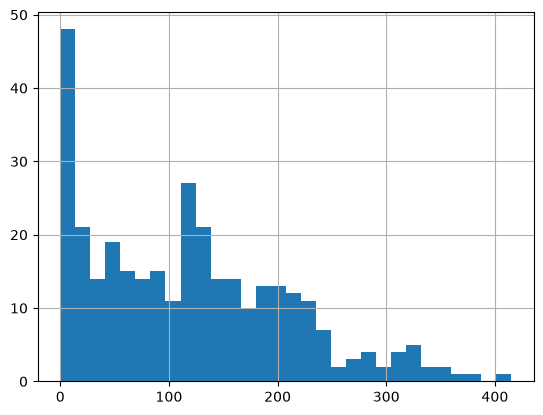

In [12]:
df = pd.read_csv("opendata-basketball/data/aggregates/acb_shotsaggregates_20252026.csv")
display(df.shape)
display(df.isna().sum()[df.isna().sum() > 0])

display(df['attempts'].describe())
display(df['attempts'].hist(bins=30))

In [13]:
thresholds = [25, 50, 75, 100]
for t in thresholds:
    n = (df['attempts'] >= t).sum()
    print(f">= {t} attempts: {n} players ({n/326*100:.1f}%)")

display(df['attempts'].quantile([0.1, 0.25, 0.5, 0.75, 0.9]))

>= 25 attempts: 261 players (80.1%)
>= 50 attempts: 235 players (72.1%)
>= 75 attempts: 202 players (62.0%)
>= 100 attempts: 178 players (54.6%)


0.10      5.00
0.25     41.00
0.50    115.00
0.75    182.75
0.90    240.00
Name: attempts, dtype: float64

In [14]:
low_attempt_players = df[df['attempts'] < 50][['attempts', 'possessions_played']].sort_values('attempts', ascending=False)
print(low_attempt_players.head(20))

     attempts  possessions_played
62         48                 349
275        46                 331
291        45                 371
82         44                 327
238        44                 352
24         44                 204
179        43                 547
19         42                 231
64         41                 187
8          41                 213
186        39                 601
151        35                 332
67         34                 445
56         33                 266
27         32                 160
57         30                 238
290        30                 241
5          30                 258
2          30                 235
322        29                 194


In [15]:
df_full = df.copy()
df = df[df['attempts'] >= 50].reset_index(drop=True)
print(df.shape)

(235, 308)


In [16]:
# Shot type distribution across the league
shot_type_cols = [c for c in df.columns if c.startswith('cst_') and c.endswith('_attempts')]
display(df[shot_type_cols].sum().sort_values(ascending=False))

# Contest level distribution
cl_cols = [c for c in df.columns if c.startswith('cl_') and c.endswith('_attempts')]
display(df[cl_cols].sum().sort_values(ascending=False))

# Zone distribution
zone_cols = [c for c in df.columns if c.startswith('zone_') and c.endswith('_attempts')]
display(df[zone_cols].sum().sort_values(ascending=False))

cst_layup_attempts              11109
cst_catch_and_shoot_attempts     7483
cst_dribble_pull_up_attempts     7186
cst_off_move_attempts            3672
cst_floater_attempts             1684
cst_hook_attempts                1257
cst_dunk_attempts                1210
cst_tip_attempts                  708
cst_stepback_attempts             657
cst_shake_and_raise_attempts      473
cst_lob_attempts                  373
cst_post_fadeaway_attempts        335
cst_heave_attempts                135
cst_leaner_attempts                92
dtype: int64

cl_plus_attempts       13770
cl_average_attempts    10320
cl_open_attempts        8229
cl_light_attempts       2625
cl_blocked_attempts     1430
dtype: int64

zone_three_attempts              15135
zone_above_break_3_attempts      11821
zone_paint_non_ra_attempts        8673
zone_restricted_area_attempts     8307
zone_wing_3_left_attempts         4046
zone_mid_range_attempts           3997
zone_wing_3_right_attempts        3960
zone_top_3_attempts               3815
zone_corner_3_attempts            3314
zone_corner_3_left_attempts       1765
zone_corner_3_right_attempts      1549
zone_other_attempts                889
zone_far_attempts                  141
zone_backcourt_attempts            125
dtype: int64

**Player Inclusion Threshold**

Minimum 50 attempts required for inclusion in analysis. 
Players below this threshold (91 of 326, ~28%) lack sufficient shot volume to construct a reliable profile across dimensions. 
Low-attempt players were verified to also have low possessions_played, confirming they are non-rotation players rather than genuine 
non-shooting role players. Working dataset: 235 players.

**Classification Types**


Shot Types:

    - cst_layup_attempts ✓
    - cst_dunk_attempts ✓
        - cst_lob_attempts - group into dunks, profile of a player who will attempt lobs is by athleticism similar to a dunker
        - cst_tip_attempts - group into dunks, profile of a player who will attempt tips is by athleticism similar to a dunker
    - cst_catch_and_shoot_attempts ✓
    - cst_perimeter_self_created ✓
        - cst_dribble_pull_up_attempts - group into perimeter_self_created, regardless of final shot type choice, the method to reaching it is ultimately the same, perimeter-isolation
        - cst_stepback_attempts - group into perimeter_self_created, regardless of final shot type choice, the method to reaching it is ultimately the same, perimeter-isolation
    - cst_post_self_created ✓
        - cst_shake_and_raise_attempts - group into post_self_created, regardless of final shot type choice, the method to reaching it is ultimately the same, post-work
        - cst_post_fadeaway_attempts - group into post_self_created, regardless of final shot type choice, the method to reaching it is ultimately the same, post-work
    - cst_off_move_attempts ✓
    - cst_floater_attempts ✓
        - cst_hook_attempts - group into floater, differentiation can be ambiguous and shot types are similar enough
    - cst_heave_attempts ✖ - too sparse and unspecialized to include
    - cst_leaner_attempts ✖ - too sparse and difficult to define to include


Contest Types:

    - cl_plus_attempts ✓
    - cl_average_attempts ✓
    - cl_open_attempts ✓
    - cl_light_attempts ✓
    - cl_blocked_attempts ✓


Zones:

    - zone_three_attempts ✖ - aggregation and thus excluded
    - zone_above_break_3_attempts ✓
    - zone_paint_non_ra_attempts ✓
    - zone_restricted_area_attempts ✓
    - zone_wing_3_left_attempts ✓
    - zone_mid_range_attempts ✓
    - zone_wing_3_right_attempts ✓
    - zone_top_3_attempts ✓
    - zone_corner_3_attempts ✖ - aggregation and thus excluded
    - zone_corner_3_left_attempts ✓
    - zone_corner_3_right_attempts ✓
    - zone_other_attempts ✖ - aggregation and thus excluded
    - zone_far_attempts ✖ - too sparce and uspecialized to include
    - zone_backcourt_attempts ✖ - too sparce and uspecialized to include